# Notebook 2 — Time-Series Risk Model (PhysioNet 2012 → Transformer with recency decay)

**Role in the pipeline.** Runs **every hour** on the most recent window of vitals and labs and returns `p_ts` (probability of in-hospital death given the data so far). In Notebook 4 it becomes the adjustment `Δ_ts = logit(p_ts) − logit(base rate)`, weighted by `α` = this model's Brier skill score.

**Windowing (as agreed)**
- Hourly bins over the first 48 h of the ICU stay.
- **Warm-up:** the first prediction is made after 5 h (window = hours 0–4).
- The window **grows** until it reaches **12 h**, then **slides** one hour at a time → predictions at hours 5, 6, …, 48 (44 per patient).
- **Label:** in-hospital death for every window. **Split by patient**, so no patient's windows appear in two splits.

**Architecture — same skeleton as the SOC `APITransformerClassifier`**
| SOC (API calls) | Here (vitals/labs) | Why |
|---|---|---|
| `nn.Embedding(vocab)` | `nn.Linear(values ‖ observed-mask ‖ hours-since-last)` | inputs are continuous and irregularly measured |
| sinusoidal position by index | sinusoidal position by **hours-ago** | the newest hour always has the same position, whatever the window length |
| fixed length 100 | 5–12 h, left-padded + padding mask | growing window during warm-up |
| mean pooling | **exponential-decay pooling** (half-life chosen on validation) | recent hours count more |
| 2-class CE with class weights | 1 logit, plain BCE | keeps probabilities close to the true rate; Platt refines them |
| Platt scaler on logits | Platt on the single logit | same |
| top API-call factors | top variables by occlusion | same purpose: evidence for the report/LLM |

**Inputs:** private dataset `medical-timeseries-data` (`set-a/b/c.tar.gz`, `Outcomes-a/b/c.txt`). **GPU (T4) recommended.**

**Outputs (`/kaggle/working/artifacts_transformer/` + zip):** weights, config, normalisation stats, calibrator, metrics (incl. `alpha`), trigger thresholds, `ts_inference.py` loader, test patients' hourly data for the demo, plots.

## 1. Setup

In [1]:
import os, sys, glob, json, math, time, shutil, tarfile, platform, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ---- paths --------------------------------------------------------------
def find_data_root():
    hits = glob.glob("/kaggle/input/**/Outcomes-a.txt", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    local = os.environ.get("PHYSIONET_DIR", ".")
    if os.path.exists(os.path.join(local, "Outcomes-a.txt")):
        return local
    raise FileNotFoundError("Outcomes-a.txt not found. Attach the 'medical-timeseries-data' dataset.")

DATA_ROOT = find_data_root()
INPUT_ROOT = "/kaggle/input" if os.path.isdir("/kaggle/input") else DATA_ROOT
EXTRACT_DIR = "/tmp/physionet2012"                 # outside /kaggle/working so 12k files don't end up in the output
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath(".")
OUT_DIR  = os.path.join(WORK_DIR, "artifacts_transformer")
PLOT_DIR = os.path.join(OUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

# ---- experiment settings -------------------------------------------------
QUICK = os.environ.get("NB2_QUICK") == "1"         # tiny run for smoke-testing only
VAL_FRAC, TEST_FRAC = 0.15, 0.15
HALF_LIFE_GRID = [3.0, 6.0] if QUICK else [3.0, 6.0, 12.0]   # hours; chosen on validation
MAX_EPOCHS     = 2 if QUICK else 25
PATIENCE       = 4
WINDOWS_PER_PATIENT_PER_EPOCH = 2 if QUICK else 8
BATCH_SIZE     = 256
LR, WEIGHT_DECAY = 5e-4, 1e-4

# trigger settings (thresholds themselves are learned from validation survivors)
TRIGGER_K_CONSECUTIVE = 3      # hours p_ts must stay >= theta
TRIGGER_RISE_HOURS    = 4      # m: look-back for the "rapid rise" rule
THETA_SURVIVOR_PCTL   = 90     # theta = this percentile of survivors' p_ts
RISE_SURVIVOR_PCTL    = 95     # delta = this percentile of survivors' m-hour rises
COOLDOWN_HOURS        = 12     # no new re-imaging within this many hours of the last one

print("data root:", DATA_ROOT, "| output:", OUT_DIR, "| quick:", QUICK)

device: cuda
data root: /kaggle/input/datasets/anarvaaa/medical-timeseries-data | output: /kaggle/working/artifacts_transformer | quick: False


## 2. Shared inference module
Same pattern as Notebook 1: everything Notebook 4 needs (record parsing, featurisation, model class, calibration, trajectory, explanation, trigger rule) lives in one file saved with the artifacts.

In [2]:
%%writefile {OUT_DIR}/ts_inference.py
"""Time-series (vitals/labs) mortality-risk model: shared code for training (NB2) and inference (NB4).

Usage later:
    import sys; sys.path.insert(0, ART_DIR)
    from ts_inference import VitalsRiskModel
    ts = VitalsRiskModel(ART_DIR)
    traj = ts.trajectory(raw_hourly)            # DataFrame: hour, window_len, p_ts, delta_ts
    top  = ts.explain(raw_hourly, end_hour=20)  # top variables for that window
    ev   = ts.triggers(traj)                    # re-imaging trigger events (with cooldown)
"""
import json
import math
import os

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

N_HOURS = 48
WINDOW = 12
WARMUP = 5
DESCRIPTORS = ["RecordID", "Age", "Gender", "Height", "ICUType", "Weight"]
VARIABLES = [
    "Albumin", "ALP", "ALT", "AST", "Bilirubin", "BUN", "Cholesterol", "Creatinine", "DiasABP", "FiO2",
    "GCS", "Glucose", "HCO3", "HCT", "HR", "K", "Lactate", "Mg", "MAP", "MechVent", "Na", "NIDiasABP",
    "NIMAP", "NISysABP", "PaCO2", "PaO2", "pH", "Platelets", "RespRate", "SaO2", "SysABP", "Temp",
    "TroponinI", "TroponinT", "Urine", "WBC",
]   # time-series Weight is left out: weight is already a baseline (XGBoost) feature
ALIASES = {"TropI": "TroponinI", "TropT": "TroponinT"}
SUM_VARS = {"Urine"}          # urine output is summed per hour, everything else averaged
VAR_INDEX = {v: i for i, v in enumerate(VARIABLES)}
N_VARS = len(VARIABLES)


# ----------------------------------------------------------------------------- parsing
def parse_record(path):
    """One PhysioNet-2012 record -> (descriptor dict, raw hourly array [48, N_VARS] with NaN, unknown-name set)."""
    desc, unknown = {}, set()
    sums = np.zeros((N_HOURS, N_VARS)); cnts = np.zeros((N_HOURS, N_VARS))
    with open(path) as f:
        next(f, None)                                   # header: Time,Parameter,Value
        for line in f:
            parts = line.strip().split(",")
            if len(parts) != 3 or not parts[1]:
                continue
            t, p, v = parts
            try:
                v = float(v); hh, mm = t.split(":"); minutes = int(hh) * 60 + int(mm)
            except ValueError:
                continue
            p = ALIASES.get(p, p)
            if p in DESCRIPTORS and minutes == 0 and p not in desc:
                desc[p] = v
                if p != "Weight":
                    continue
            j = VAR_INDEX.get(p)
            if j is None:
                if p not in DESCRIPTORS:
                    unknown.add(p)
                continue
            if v < 0:                                   # -1 = missing (all valid values are >= 0)
                continue
            h = min(minutes // 60, N_HOURS - 1)
            sums[h, j] += v; cnts[h, j] += 1
    raw = np.full((N_HOURS, N_VARS), np.nan)
    seen = cnts > 0
    raw[seen] = sums[seen]
    mean_cols = np.array([v not in SUM_VARS for v in VARIABLES])
    avg = np.divide(sums, np.where(seen, cnts, 1))
    raw[:, mean_cols] = np.where(seen[:, mean_cols], avg[:, mean_cols], np.nan)
    return desc, raw, unknown


# ----------------------------------------------------------------------------- features
def featurize(raw, stats):
    """raw [N,48,V] (NaN = not measured) -> X [N,48,3V] = (z-score carried forward | measured-this-hour | hours-since-last/12).
    Strictly causal: hour t only uses hours <= t."""
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim == 2:
        raw = raw[None]
    lo, hi = np.array(stats["clip_lo"]), np.array(stats["clip_hi"])
    mu, sd = np.array(stats["mean"]), np.array(stats["std"])
    mask = ~np.isnan(raw)
    z = (np.clip(raw, lo, hi) - mu) / sd
    t_idx = np.arange(N_HOURS)[None, :, None]
    last = np.where(mask, t_idx, -1)
    last = np.maximum.accumulate(last, axis=1)                       # index of last observation (or -1)
    ever = last >= 0
    z_ff = np.take_along_axis(np.nan_to_num(z, nan=0.0), np.clip(last, 0, None), axis=1)
    z_ff = np.where(ever, z_ff, 0.0)                                 # never measured -> population mean
    since = np.where(ever, t_idx - last, WINDOW)
    since = np.minimum(since, WINDOW) / WINDOW
    return np.concatenate([z_ff, mask.astype(float), since], axis=-1).astype(np.float32)


def make_batch(X, pid, end, window=WINDOW):
    """Gather right-aligned windows. X: [N,48,D] tensor; pid, end: LongTensors [B].
    Window ending at hour `end` covers hours [end-window, end). Returns x [B,window,D], pad_mask [B,window]."""
    pos = torch.arange(window, device=X.device)
    hours = end[:, None] - window + pos[None, :]
    valid = hours >= 0
    xb = X[pid[:, None], hours.clamp(min=0)] * valid.unsqueeze(-1)
    return xb, ~valid


# ----------------------------------------------------------------------------- model
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=64):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe)

    def forward(self, x, hours_ago):              # hours_ago: [L] long
        return x + self.pe[hours_ago].unsqueeze(0)


class VitalsTransformerClassifier(nn.Module):
    """SOC APITransformerClassifier skeleton, adapted to continuous vitals + recency-decay pooling."""

    def __init__(self, n_inputs, d_model=128, nhead=4, num_layers=2, dim_feedforward=256,
                 dropout=0.12, half_life=6.0):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(n_inputs, d_model), nn.LayerNorm(d_model))
        self.pos_encoder = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
                                           dropout=dropout, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(layer, num_layers=num_layers, enable_nested_tensor=False)
        self.classifier = nn.Sequential(nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
        self.register_buffer("half_life", torch.tensor(float(half_life)))

    def decay_weights(self, pad_mask):
        L = pad_mask.size(1)
        hours_ago = torch.arange(L - 1, -1, -1, device=pad_mask.device).float()
        w = torch.exp(-math.log(2.0) * hours_ago / self.half_life).expand_as(pad_mask)
        w = w.masked_fill(pad_mask, 0.0)
        return w / w.sum(dim=1, keepdim=True)

    def forward(self, x, pad_mask):
        L = x.size(1)
        hours_ago = torch.arange(L - 1, -1, -1, device=x.device)
        h = self.pos_encoder(self.input_proj(x), hours_ago)
        h = self.transformer_encoder(h, src_key_padding_mask=pad_mask)
        w = self.decay_weights(pad_mask)
        pooled = (h * w.unsqueeze(-1)).sum(dim=1)
        return self.classifier(pooled).squeeze(-1)       # raw logit


# ----------------------------------------------------------------------------- helpers
def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


def detect_triggers(hours, p, theta, k, m, delta, cooldown, rise_floor=0.0, last_image_hour=None):
    """Re-imaging rule: p_ts >= theta for k consecutive hours, OR a rise >= delta over m hours that ends
    at p_ts >= rise_floor. No new trigger within `cooldown` hours of the previous image; pass
    last_image_hour (e.g. the t=0 image) so the first cooldown starts from that image."""
    events, run = [], 0
    last = -10**9 if last_image_hour is None else last_image_hour
    p = np.asarray(p, dtype=float)
    for i, (h, v) in enumerate(zip(hours, p)):
        run = run + 1 if v >= theta else 0
        sustained = run >= k
        rise = i >= m and (v - p[i - m]) >= delta and v >= rise_floor
        if (sustained or rise) and h - last >= cooldown:
            reason = "sustained+rise" if (sustained and rise) else ("sustained" if sustained else "rapid rise")
            events.append({"hour": int(h), "p_ts": float(v), "reason": reason})
            last = h
    return events


class VitalsRiskModel:
    """Loads every Notebook-2 artifact from one folder."""

    def __init__(self, art_dir, device=None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        J = lambda f: json.load(open(os.path.join(art_dir, f)))
        self.cfg, self.stats, self.cal, self.metrics = J("model_config.json"), J("norm_stats.json"), J("calibrator.json"), J("metrics.json")
        self.trigger_cfg = self.cfg["triggers"]
        a = self.cfg["architecture"]
        self.model = VitalsTransformerClassifier(**a).to(self.device)
        self.model.load_state_dict(torch.load(os.path.join(art_dir, "vitals_transformer.pth"), map_location=self.device))
        self.model.eval()
        self.base_rate = self.metrics["base_rate_train"]
        self.alpha = self.metrics["alpha"]

    def _logits(self, X, pid, end):
        with torch.no_grad():
            xb, pad = make_batch(X, pid, end, self.cfg["window"])
            return self.model(xb, pad).cpu().numpy()

    def calibrate(self, z):
        return sigmoid(self.cal["a"] * np.asarray(z) + self.cal["b"])

    def delta(self, p):
        return logit(p) - logit(self.base_rate)

    def trajectory(self, raw_hourly, start=None, end=N_HOURS):
        """raw_hourly [48, V] -> one row per hour from warm-up end to `end`."""
        start = start or self.cfg["warmup"]
        X = torch.tensor(featurize(raw_hourly, self.stats), device=self.device)
        ends = torch.arange(start, end + 1, device=self.device)
        z = self._logits(X, torch.zeros_like(ends), ends)
        p = self.calibrate(z)
        hrs = ends.cpu().numpy()
        return pd.DataFrame({"hour": hrs, "window_len": np.minimum(hrs, self.cfg["window"]),
                             "logit_raw": z, "p_ts": p, "delta_ts": self.delta(p)})

    def explain(self, raw_hourly, end_hour, top_k=3):
        """Occlusion: remove one variable from the window at a time; contribution = drop in raw logit."""
        W = self.cfg["window"]
        X = torch.tensor(featurize(raw_hourly, self.stats), device=self.device)
        xb, pad = make_batch(X, torch.tensor([0], device=self.device), torch.tensor([end_hour], device=self.device), W)
        V = N_VARS
        occl = xb.repeat(V + 1, 1, 1)
        for j in range(V):
            occl[j + 1, :, j] = 0.0; occl[j + 1, :, V + j] = 0.0; occl[j + 1, :, 2 * V + j] = 1.0
        occl = occl * (~pad).unsqueeze(-1).repeat(V + 1, 1, 1)
        with torch.no_grad():
            z = self.model(occl, pad.repeat(V + 1, 1)).cpu().numpy()
        contrib = z[0] - z[1:]
        s, e = max(0, end_hour - W), end_hour
        win = np.asarray(raw_hourly)[s:e]
        rows = []
        for j, v in enumerate(VARIABLES):
            obs = win[:, j][~np.isnan(win[:, j])]
            rows.append({"variable": v, "contribution": float(contrib[j]), "n_obs": int(len(obs)),
                         "first": float(obs[0]) if len(obs) else np.nan, "last": float(obs[-1]) if len(obs) else np.nan})
        df = pd.DataFrame(rows)
        df["trend"] = np.where(df["n_obs"] >= 2, np.sign(df["last"] - df["first"]).map({1.0: "rising", -1.0: "falling", 0.0: "flat"}), "")
        return df.reindex(df["contribution"].abs().sort_values(ascending=False).index).head(top_k).reset_index(drop=True)

    def triggers(self, traj, last_image_hour="start"):
        """last_image_hour='start' treats the t=0 image as the first image (cooldown starts there)."""
        c = self.trigger_cfg
        if last_image_hour == "start":
            last_image_hour = int(traj["hour"].iloc[0])
        return detect_triggers(traj["hour"].values, traj["p_ts"].values, c["theta"], c["k_consecutive"],
                               c["rise_hours"], c["rise_delta"], c["cooldown_hours"],
                               rise_floor=c.get("rise_floor", 0.0), last_image_hour=last_image_hour)

Writing /kaggle/working/artifacts_transformer/ts_inference.py


In [3]:
sys.dont_write_bytecode = True
sys.path.insert(0, OUT_DIR)
import importlib, ts_inference
importlib.reload(ts_inference)
from ts_inference import (N_HOURS, WINDOW, WARMUP, VARIABLES, N_VARS, parse_record, featurize, make_batch,
                          VitalsTransformerClassifier, logit, sigmoid, detect_triggers)
print(f"{N_VARS} time-series variables | window {WINDOW} h | warm-up {WARMUP} h")

36 time-series variables | window 12 h | warm-up 5 h


## 3. Locate / extract records and parse them into hourly arrays

In [4]:
def record_files():
    # Kaggle may have auto-extracted the archives; otherwise extract the .tar.gz files once into /tmp
    files = [p for p in glob.glob(os.path.join(INPUT_ROOT, "**", "*.txt"), recursive=True)
             if os.path.basename(p)[:-4].isdigit()]
    if len(files) < 100:
        os.makedirs(EXTRACT_DIR, exist_ok=True)
        for tgz in sorted(glob.glob(os.path.join(INPUT_ROOT, "**", "set-*.tar.gz"), recursive=True)):
            print("extracting", tgz)
            with tarfile.open(tgz) as tf:
                tf.extractall(EXTRACT_DIR)
        files = [p for p in glob.glob(os.path.join(EXTRACT_DIR, "**", "*.txt"), recursive=True)
                 if os.path.basename(p)[:-4].isdigit()]
    uniq = {}
    for p in sorted(files):
        uniq.setdefault(int(os.path.basename(p)[:-4]), p)   # de-duplicate if both forms exist
    return uniq

files = record_files()
print("record files:", len(files))

outcomes = pd.concat([pd.read_csv(p) for p in sorted(glob.glob(os.path.join(DATA_ROOT, "Outcomes-*.txt")))],
                     ignore_index=True).drop_duplicates("RecordID")
outcomes.columns = [c.strip() for c in outcomes.columns]
LABEL_COL = [c for c in outcomes.columns if "death" in c.lower()][0]
print("outcome rows:", len(outcomes), "| label column:", LABEL_COL)

record files: 12000
outcome rows: 12000 | label column: In-hospital_death


In [5]:
t0 = time.time()
ids, raws, descs, unknown_all = [], [], [], set()
for i, (rid, path) in enumerate(files.items()):
    d, r, unk = parse_record(path)
    ids.append(rid); raws.append(r); descs.append(d); unknown_all |= unk
    if (i + 1) % 3000 == 0:
        print(f"  parsed {i+1}/{len(files)}  ({time.time()-t0:.0f}s)")
RAW = np.stack(raws).astype(np.float32)                    # [N, 48, V]
desc_df = pd.DataFrame(descs).assign(RecordID=ids)
print(f"parsed {len(ids)} records in {time.time()-t0:.0f}s | unknown parameter names: {sorted(unknown_all) or 'none'}")

meta = desc_df.merge(outcomes, on="RecordID", how="inner")
keep = np.isin(ids, meta["RecordID"].values)
RAW = RAW[keep]; ids = np.array(ids)[keep]
meta = meta.set_index("RecordID").loc[ids].reset_index()
y_all = meta[LABEL_COL].astype(int).values
print("patients with outcome:", len(ids), "| in-hospital death rate: %.3f" % y_all.mean())

obs_rate = pd.Series((~np.isnan(RAW)).mean(axis=(0, 1)), index=VARIABLES).sort_values(ascending=False)
pt_rate = pd.Series((~np.isnan(RAW)).any(axis=1).mean(axis=0), index=VARIABLES)
display(pd.DataFrame({"hours_with_measurement_%": obs_rate * 100, "patients_ever_measured_%": pt_rate[obs_rate.index] * 100}).round(1).T)

  parsed 3000/12000  (10s)
  parsed 6000/12000  (20s)
  parsed 9000/12000  (29s)
  parsed 12000/12000  (39s)
parsed 12000 records in 39s | unknown parameter names: none
patients with outcome: 12000 | in-hospital death rate: 0.142


,HR,Urine,SysABP,DiasABP,MAP,NISysABP,NIDiasABP,NIMAP,Temp,GCS,...,Lactate,SaO2,Bilirubin,AST,ALT,ALP,Albumin,TroponinT,TroponinI,Cholesterol
hours_with_measurement_%,90.1,69.2,54.1,54.1,53.8,42.1,42.0,41.4,37.1,32.0,...,4.1,4.0,1.7,1.7,1.7,1.6,1.3,1.1,0.2,0.2
patients_ever_measured_%,98.5,97.4,70.2,70.2,70.1,87.6,87.2,87.2,98.5,98.5,...,54.8,44.7,43.4,43.4,43.4,42.5,40.6,22.0,4.7,7.9


## 4. Patient-level split and normalisation (fitted on training patients only)

In [6]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(ids))
idx_trval, idx_te = train_test_split(idx, test_size=TEST_FRAC, stratify=y_all, random_state=SEED)
idx_tr, idx_va = train_test_split(idx_trval, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                  stratify=y_all[idx_trval], random_state=SEED)
for n, s in [("train", idx_tr), ("val", idx_va), ("test", idx_te)]:
    print(f"{n:5s} patients={len(s):5d}  death rate={y_all[s].mean():.3f}")

tr_obs = RAW[idx_tr].reshape(-1, N_VARS)
clip_lo = np.nanpercentile(tr_obs, 0.5, axis=0); clip_hi = np.nanpercentile(tr_obs, 99.5, axis=0)
clipped = np.clip(tr_obs, clip_lo, clip_hi)
mu = np.nanmean(clipped, axis=0); sd = np.nanstd(clipped, axis=0)
sd = np.where((sd < 1e-6) | np.isnan(sd), 1.0, sd); mu = np.nan_to_num(mu)
clip_lo = np.nan_to_num(clip_lo, nan=-1e9); clip_hi = np.nan_to_num(clip_hi, nan=1e9)
NORM_STATS = {"variables": VARIABLES, "clip_lo": clip_lo.tolist(), "clip_hi": clip_hi.tolist(),
              "mean": mu.tolist(), "std": sd.tolist()}

X_ALL = featurize(RAW, NORM_STATS)                       # [N, 48, 3V]
print("feature tensor:", X_ALL.shape, f"({X_ALL.nbytes/1e6:.0f} MB)")
X_T = torch.tensor(X_ALL, device=device)
Y_T = torch.tensor(y_all, dtype=torch.float32, device=device)
N_INPUTS = X_ALL.shape[-1]

train patients= 8399  death rate=0.142
val   patients= 1801  death rate=0.142
test  patients= 1800  death rate=0.142
feature tensor: (12000, 48, 108) (249 MB)


## 5. Training (one model per decay half-life; best chosen by validation log-loss)

In [7]:
END_HOURS = np.arange(WARMUP, N_HOURS + 1)                # 5 ... 48  -> 44 windows per patient

def all_pairs(patients):
    return np.stack([np.repeat(patients, len(END_HOURS)), np.tile(END_HOURS, len(patients))], axis=1)

PAIRS_VA, PAIRS_TE = all_pairs(idx_va), all_pairs(idx_te)

@torch.no_grad()
def predict_pairs(model, pairs, bs=2048):
    model.eval(); out = []
    for s in range(0, len(pairs), bs):
        b = torch.tensor(pairs[s:s + bs], device=device)
        xb, pad = make_batch(X_T, b[:, 0], b[:, 1], WINDOW)
        out.append(model(xb, pad).float().cpu().numpy())
    return np.concatenate(out)

bce = nn.BCEWithLogitsLoss()

def train_one(half_life):
    set_seed()
    arch = dict(n_inputs=N_INPUTS, d_model=128, nhead=4, num_layers=2, dim_feedforward=256,
                dropout=0.12, half_life=half_life)
    model = VitalsTransformerClassifier(**arch).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    rng = np.random.default_rng(SEED)
    y_va_w = y_all[PAIRS_VA[:, 0]]
    best, best_state, wait, hist = np.inf, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        ends = rng.integers(WARMUP, N_HOURS + 1, size=(len(idx_tr), WINDOWS_PER_PATIENT_PER_EPOCH))
        pairs = np.stack([np.repeat(idx_tr, WINDOWS_PER_PATIENT_PER_EPOCH), ends.ravel()], 1)
        pairs = pairs[rng.permutation(len(pairs))]
        tot = 0.0
        for s in range(0, len(pairs), BATCH_SIZE):
            b = torch.tensor(pairs[s:s + BATCH_SIZE], device=device)
            xb, pad = make_batch(X_T, b[:, 0], b[:, 1], WINDOW)
            loss = bce(model(xb, pad), Y_T[b[:, 0]])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(b)
        z_va = predict_pairs(model, PAIRS_VA)
        va_loss = float(bce(torch.tensor(z_va), torch.tensor(y_va_w, dtype=torch.float32)))
        va_auc = roc_auc_score(y_va_w, z_va)
        hist.append({"half_life": half_life, "epoch": epoch, "train_loss": tot / len(pairs), "val_loss": va_loss, "val_auroc": va_auc})
        print(f"  hl={half_life:>4} ep{epoch:02d} train={tot/len(pairs):.4f} val={va_loss:.4f} auroc={va_auc:.4f}")
        if va_loss < best - 1e-4:
            best, best_state, wait = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, arch, best, hist

from sklearn.metrics import roc_auc_score
runs, history = {}, []
t0 = time.time()
for hl in HALF_LIFE_GRID:
    print(f"half-life {hl} h")
    m, arch, best, hist = train_one(hl)
    runs[hl] = (m, arch, best); history += hist
print(f"training done in {(time.time()-t0)/60:.1f} min")

hist_df = pd.DataFrame(history)
summary = hist_df.groupby("half_life").agg(best_val_loss=("val_loss", "min"), best_val_auroc=("val_auroc", "max"), epochs=("epoch", "max"))
display(summary.round(4))
BEST_HL = float(summary["best_val_loss"].idxmin())
model, ARCH, _ = runs[BEST_HL]
print("chosen half-life:", BEST_HL, "h")

half-life 3.0 h
  hl= 3.0 ep01 train=0.3382 val=0.3229 auroc=0.8196
  hl= 3.0 ep02 train=0.3049 val=0.3206 auroc=0.8256
  hl= 3.0 ep03 train=0.2876 val=0.3230 auroc=0.8237
  hl= 3.0 ep04 train=0.2687 val=0.3268 auroc=0.8226
  hl= 3.0 ep05 train=0.2506 val=0.3623 auroc=0.8142
  hl= 3.0 ep06 train=0.2294 val=0.3583 auroc=0.8061
half-life 6.0 h
  hl= 6.0 ep01 train=0.3382 val=0.3222 auroc=0.8204
  hl= 6.0 ep02 train=0.3055 val=0.3216 auroc=0.8250
  hl= 6.0 ep03 train=0.2878 val=0.3219 auroc=0.8243
  hl= 6.0 ep04 train=0.2688 val=0.3239 auroc=0.8247
  hl= 6.0 ep05 train=0.2499 val=0.3662 auroc=0.8116
  hl= 6.0 ep06 train=0.2293 val=0.3544 auroc=0.8064
half-life 12.0 h
  hl=12.0 ep01 train=0.3382 val=0.3225 auroc=0.8204
  hl=12.0 ep02 train=0.3057 val=0.3207 auroc=0.8272
  hl=12.0 ep03 train=0.2880 val=0.3205 auroc=0.8267
  hl=12.0 ep04 train=0.2686 val=0.3247 auroc=0.8236
  hl=12.0 ep05 train=0.2501 val=0.3616 auroc=0.8146
  hl=12.0 ep06 train=0.2290 val=0.3612 auroc=0.8028
  hl=12.0 ep07 

,best_val_loss,best_val_auroc,epochs
half_life,,,
3.0,0.3206,0.8256,6
6.0,0.3216,0.8250,6
12.0,0.3205,0.8272,7


chosen half-life: 12.0 h


Half-life comparison (test):


,chosen,AUROC (windows),AUPRC (windows),Brier (windows),AUROC (patients @48h)
half_life_h,,,,,
3.0,False,0.8096,0.4488,0.0997,0.8366
6.0,False,0.8117,0.4559,0.0992,0.8376
12.0,True,0.8219,0.4530,0.0992,0.8488



Chosen half-life = 12 h | test AUROC windows = 0.8219 | patients @48h = 0.8488
'everyone survives' accuracy = 0.858


accuracy  balanced_accuracy  precision (PPV)  recall / sensitivity  specificity      F1     NPV      TP       FP      FN       TN
windows       0.5             0.8689             0.6309           0.5758                0.2982       0.9636  0.3929  0.8923  3359.0   2475.0  7905.0  65461.0
              Youden 0.135    0.7478             0.7404           0.3269                0.7300       0.7508  0.4516  0.9437  8223.0  16933.0  3041.0  51003.0
patients @48h 0.5             0.8756             0.6521           0.6127                0.3398       0.9644  0.4372  0.8981    87.0     55.0   169.0   1489.0
              Youden 0.135    0.7717             0.7529           0.3529                0.7266       0.7791  0.4751  0.9450   186.0    341.0    70.0   1203.0


Classification report (test windows, Youden threshold):
              precision    recall  f1-score   support

    Survived     0.9437    0.7508    0.8363     67936
        Died     0.3269    0.7300    0.4516     11264

    accuracy                         0.7478     79200
   macro avg     0.6353    0.7404    0.6439     79200
weighted avg     0.8560    0.7478    0.7815     79200



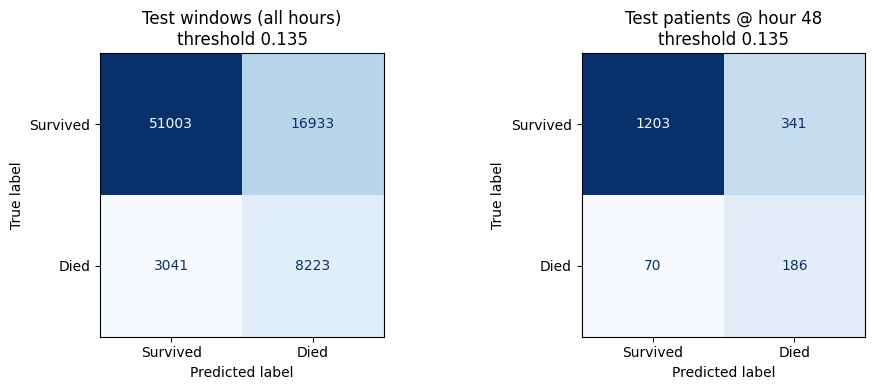

In [8]:
# ---- Metrics after choosing the best half-life (raw model, before Platt calibration) ----
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             brier_score_loss, roc_curve, classification_report)

y_va_cm, y_te_cm = y_all[PAIRS_VA[:, 0]], y_all[PAIRS_TE[:, 0]]
last_cm = PAIRS_TE[:, 1] == N_HOURS                      # one window per patient: the final one (hour 48)

def threshold_metrics(y, p, t):
    yhat = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, yhat), "balanced_accuracy": balanced_accuracy_score(y, yhat),
            "precision (PPV)": precision_score(y, yhat, zero_division=0),
            "recall / sensitivity": recall_score(y, yhat, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1": f1_score(y, yhat, zero_division=0), "NPV": tn / (tn + fn) if (tn + fn) else np.nan,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

# 1) all half-life candidates side by side (threshold-free metrics, test windows)
cmp_rows = []
for hl, (m_hl, _, _) in runs.items():
    p_hl = sigmoid(predict_pairs(m_hl, PAIRS_TE))
    cmp_rows.append({"half_life_h": hl, "chosen": hl == BEST_HL,
                     "AUROC (windows)": roc_auc_score(y_te_cm, p_hl), "AUPRC (windows)": average_precision_score(y_te_cm, p_hl),
                     "Brier (windows)": brier_score_loss(y_te_cm, p_hl),
                     "AUROC (patients @48h)": roc_auc_score(y_te_cm[last_cm], p_hl[last_cm])})
print("Half-life comparison (test):")
display(pd.DataFrame(cmp_rows).set_index("half_life_h").round(4))

# 2) chosen model: threshold metrics at 0.5 and at the Youden threshold from validation
p_va_cm = sigmoid(predict_pairs(model, PAIRS_VA))
p_te_cm = sigmoid(predict_pairs(model, PAIRS_TE))
f_, t_, th_ = roc_curve(y_va_cm, p_va_cm)
thr_youden_cm = float(th_[np.argmax(t_ - f_)])

rows = {}
for scope, (yy, pp) in {"windows": (y_te_cm, p_te_cm), "patients @48h": (y_te_cm[last_cm], p_te_cm[last_cm])}.items():
    for name, t in {"0.5": 0.5, f"Youden {thr_youden_cm:.3f}": thr_youden_cm}.items():
        rows[(scope, name)] = threshold_metrics(yy, pp, t)
print(f"\nChosen half-life = {BEST_HL:g} h | test AUROC windows = {roc_auc_score(y_te_cm, p_te_cm):.4f} | "
      f"patients @48h = {roc_auc_score(y_te_cm[last_cm], p_te_cm[last_cm]):.4f}")
print(f"'everyone survives' accuracy = {1 - y_te_cm.mean():.3f}")
display(pd.DataFrame(rows).T.round(4))

print("\nClassification report (test windows, Youden threshold):")
print(classification_report(y_te_cm, (p_te_cm >= thr_youden_cm).astype(int), target_names=["Survived", "Died"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, yy, pp) in zip(axes, [("Test windows (all hours)", y_te_cm, p_te_cm),
                                      ("Test patients @ hour 48", y_te_cm[last_cm], p_te_cm[last_cm])]):
    ConfusionMatrixDisplay(confusion_matrix(yy, (pp >= thr_youden_cm).astype(int), labels=[0, 1]),
                           display_labels=["Survived", "Died"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{title}\nthreshold {thr_youden_cm:.3f}")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/confusion_matrix_raw.png", dpi=150); plt.show()

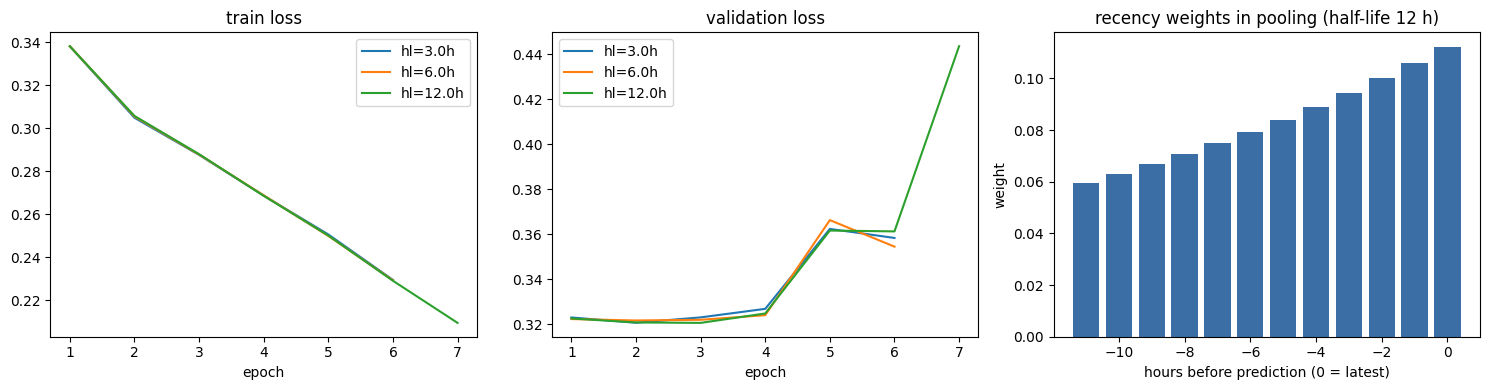

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for hl, g in hist_df.groupby("half_life"):
    axes[0].plot(g.epoch, g.train_loss, label=f"hl={hl}h")
    axes[1].plot(g.epoch, g.val_loss, label=f"hl={hl}h")
axes[0].set(title="train loss", xlabel="epoch"); axes[1].set(title="validation loss", xlabel="epoch")
axes[0].legend(); axes[1].legend()
with torch.no_grad():
    w = model.decay_weights(torch.zeros(1, WINDOW, dtype=torch.bool, device=device)).cpu().numpy()[0]
axes[2].bar(np.arange(-WINDOW + 1, 1), w, color="#3b6ea5")
axes[2].set(title=f"recency weights in pooling (half-life {BEST_HL:g} h)", xlabel="hours before prediction (0 = latest)", ylabel="weight")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/training_and_decay.png", dpi=150); plt.show()

## 6. Calibration, metrics and α
Platt scaling on the raw logit, fitted on validation windows. **α = Brier skill score on test windows** (reference = always predicting the training death rate), clipped to [0, 1].

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, roc_curve)

z_va, z_te = predict_pairs(model, PAIRS_VA), predict_pairs(model, PAIRS_TE)
y_va_w, y_te_w = y_all[PAIRS_VA[:, 0]], y_all[PAIRS_TE[:, 0]]

platt = LogisticRegression(C=1e6, max_iter=1000).fit(z_va.reshape(-1, 1), y_va_w)
CAL_A, CAL_B = float(platt.coef_[0, 0]), float(platt.intercept_[0])
cal = lambda z: sigmoid(CAL_A * z + CAL_B)
p_va, p_te = cal(z_va), cal(z_te)
print(f"Platt: p = sigmoid({CAL_A:.4f} * z + {CAL_B:.4f})")

BASE_RATE_TRAIN = float(y_all[idx_tr].mean())

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); i = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    return float(sum(abs(p[i == b].mean() - y[i == b].mean()) * (i == b).mean() for b in range(bins) if (i == b).any()))

def evaluate(y, p):
    brier = brier_score_loss(y, p); ref = brier_score_loss(y, np.full_like(p, BASE_RATE_TRAIN))
    return dict(n=int(len(y)), prevalence=float(y.mean()), auroc=float(roc_auc_score(y, p)),
                auprc=float(average_precision_score(y, p)), brier=float(brier), brier_reference=float(ref),
                brier_skill_score=float(1 - brier / ref), log_loss=float(log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))), ece=ece(y, p))

results = {"val": {"raw": evaluate(y_va_w, sigmoid(z_va)), "calibrated": evaluate(y_va_w, p_va)},
           "test": {"raw": evaluate(y_te_w, sigmoid(z_te)), "calibrated": evaluate(y_te_w, p_te)}}

# patient-level view at the last window (hour 48) -- comparable to the original challenge setting
last = PAIRS_TE[:, 1] == N_HOURS
results["test_patient_level_hour48"] = evaluate(y_te_w[last], p_te[last])

ALPHA = float(np.clip(results["test"]["calibrated"]["brier_skill_score"], 0, 1))
display(pd.DataFrame({"val/raw": results["val"]["raw"], "val/calibrated": results["val"]["calibrated"],
                       "test/raw": results["test"]["raw"], "test/calibrated": results["test"]["calibrated"],
                       "test patients @48h": results["test_patient_level_hour48"]}).T.round(4))
print(f"\nα (reliability weight) = clip(BSS_test, 0, 1) = {ALPHA:.4f}")

Platt: p = sigmoid(0.7775 * z + -0.3020)


,n,prevalence,auroc,auprc,brier,brier_reference,brier_skill_score,log_loss,ece
val/raw,79244.0,0.1421,0.8267,0.4748,0.0979,0.1219,0.1970,0.3205,0.0231
val/calibrated,79244.0,0.1421,0.8267,0.4748,0.0964,0.1219,0.2092,0.3158,0.0058
test/raw,79200.0,0.1422,0.8219,0.4530,0.0992,0.1220,0.1870,0.3276,0.0285
test/calibrated,79200.0,0.1422,0.8219,0.4530,0.0975,0.1220,0.2009,0.3203,0.0078
test patients @48h,1800.0,0.1422,0.8488,0.5078,0.0921,0.1220,0.2450,0.3017,0.0186



α (reliability weight) = clip(BSS_test, 0, 1) = 0.2009


Youden threshold (val) = 0.1483 | balanced accuracy (test windows) = 0.7404
'everyone survives' accuracy would be 0.858

              precision    recall  f1-score   support

    Survived     0.9437    0.7508    0.8363     67936
        Died     0.3269    0.7300    0.4516     11264

    accuracy                         0.7478     79200
   macro avg     0.6353    0.7404    0.6439     79200
weighted avg     0.8560    0.7478    0.7815     79200



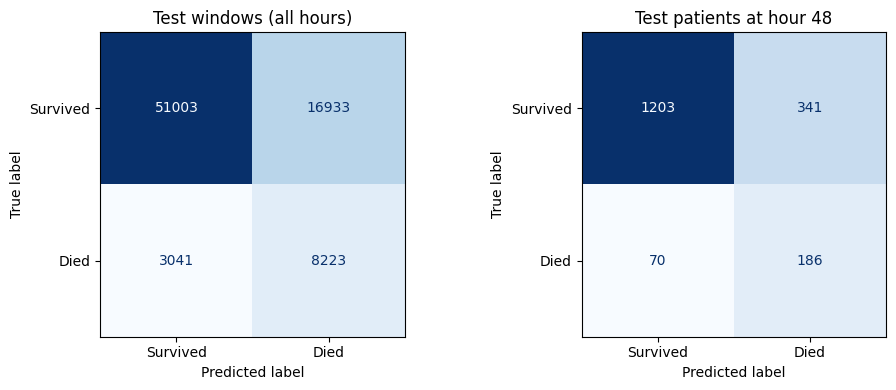

In [11]:
# Confusion matrix and classification report (window level, test) at the Youden threshold from validation
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, balanced_accuracy_score

fpr_v, tpr_v, thr_v = roc_curve(y_va_w, p_va)
DECISION_THRESHOLD = float(thr_v[np.argmax(tpr_v - fpr_v)])
yhat_te = (p_te >= DECISION_THRESHOLD).astype(int)
print(f"Youden threshold (val) = {DECISION_THRESHOLD:.4f} | balanced accuracy (test windows) = {balanced_accuracy_score(y_te_w, yhat_te):.4f}")
print(f"'everyone survives' accuracy would be {1 - y_te_w.mean():.3f}\n")
print(classification_report(y_te_w, yhat_te, target_names=["Survived", "Died"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te_w, yhat_te), display_labels=["Survived", "Died"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Test windows (all hours)")
yhat_48 = (p_te[last] >= DECISION_THRESHOLD).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_te_w[last], yhat_48), display_labels=["Survived", "Died"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title("Test patients at hour 48")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/confusion_matrix.png", dpi=150); plt.show()

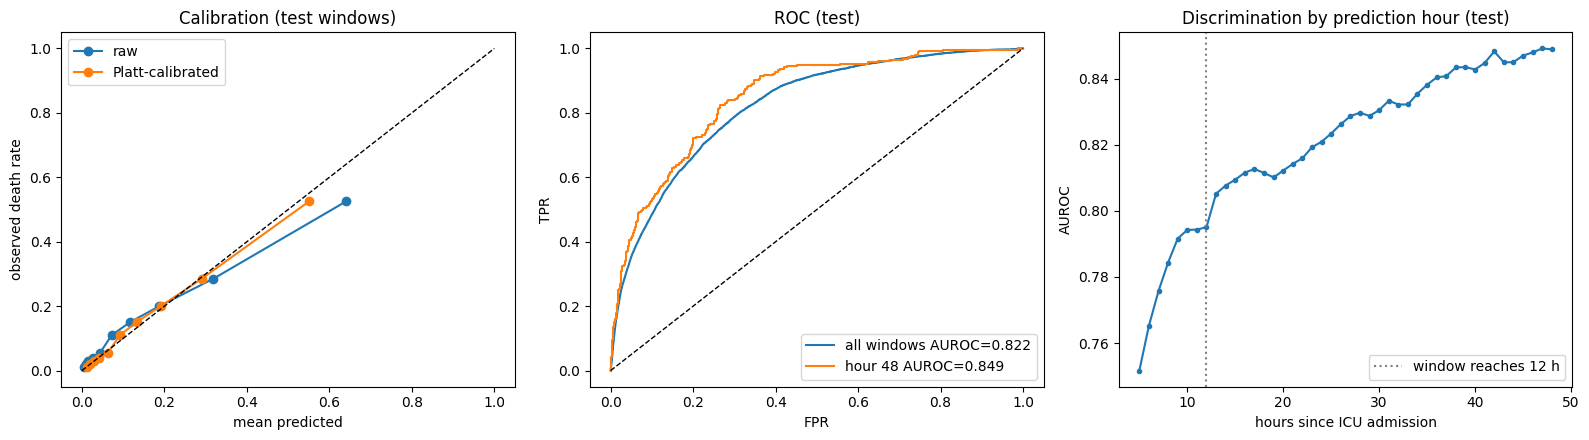

In [12]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for p, lab in [(sigmoid(z_te), "raw"), (p_te, "Platt-calibrated")]:
    fr, mp = calibration_curve(y_te_w, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, fr, marker="o", label=lab)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(xlabel="mean predicted", ylabel="observed death rate", title="Calibration (test windows)")
axes[0].legend()
f, t, _ = roc_curve(y_te_w, p_te)
axes[1].plot(f, t, label=f"all windows AUROC={results['test']['calibrated']['auroc']:.3f}")
f, t, _ = roc_curve(y_te_w[last], p_te[last])
axes[1].plot(f, t, label=f"hour 48 AUROC={results['test_patient_level_hour48']['auroc']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set(xlabel="FPR", ylabel="TPR", title="ROC (test)"); axes[1].legend()

by_hour = pd.DataFrame({"hour": PAIRS_TE[:, 1], "y": y_te_w, "p": p_te}).groupby("hour").apply(
    lambda g: pd.Series({"auroc": roc_auc_score(g.y, g.p), "brier": brier_score_loss(g.y, g.p)}))
axes[2].plot(by_hour.index, by_hour.auroc, marker=".")
axes[2].axvline(WINDOW, color="grey", ls=":", label="window reaches 12 h")
axes[2].set(xlabel="hours since ICU admission", ylabel="AUROC", title="Discrimination by prediction hour (test)"); axes[2].legend()
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/calibration_roc_byhour.png", dpi=150); plt.show()

## 7. Re-imaging trigger thresholds (learned from validation **survivors**)
- `θ` = 90th percentile of survivors' `p_ts` → a survivor sits above θ only 10% of the time.
- `δ` = 95th percentile of survivors' 4-hour rise in `p_ts`.
- Trigger = `p_ts ≥ θ` for 3 consecutive hours **or** a rise ≥ δ within 4 hours; 12-hour cooldown after each trigger.

In [13]:
# ---- Section 7: re-imaging trigger thresholds, tuned at PATIENT level on validation ----
import functools
from ts_inference import detect_triggers as _detect_triggers_base

TARGET_SURVIVOR_TRIGGER_RATE = 0.20     # at most 20% of validation survivors may get an extra image in 48 h
THETA_PCTL_GRID = [85, 90, 92.5, 95, 97.5]   # theta = percentile of survivors' p_ts (all windows)
RISE_PCTL_GRID  = [95, 97.5, 99, 99.5]       # delta = percentile of survivors' m-hour rises
RISE_FLOOR = BASE_RATE_TRAIN            # a rise only counts if it ends above the average patient's risk
INITIAL_IMAGE_HOUR = WARMUP             # the t=0 image starts the first cooldown

P_VA = p_va.reshape(len(idx_va), len(END_HOURS))
P_TE = p_te.reshape(len(idx_te), len(END_HOURS))
surv_va = y_all[idx_va] == 0
surv_p = P_VA[surv_va]
surv_rises = surv_p[:, TRIGGER_RISE_HOURS:] - surv_p[:, :-TRIGGER_RISE_HOURS]

def trigger_rates(P, y, theta, delta):
    n_ev = np.array([len(_detect_triggers_base(END_HOURS, traj, theta, TRIGGER_K_CONSECUTIVE, TRIGGER_RISE_HOURS,
                                               delta, COOLDOWN_HOURS, rise_floor=RISE_FLOOR,
                                               last_image_hour=INITIAL_IMAGE_HOUR)) for traj in P])
    return float((n_ev[y == 0] > 0).mean()), float((n_ev[y == 1] > 0).mean())

grid = []
for tp in THETA_PCTL_GRID:
    for rp in RISE_PCTL_GRID:
        theta, delta = float(np.percentile(surv_p, tp)), float(np.percentile(surv_rises, rp))
        s_rate, d_rate = trigger_rates(P_VA, y_all[idx_va], theta, delta)
        grid.append({"theta_pctl": tp, "rise_pctl": rp, "theta": theta, "delta": delta,
                     "survivors_triggered": s_rate, "deaths_triggered": d_rate})
grid = pd.DataFrame(grid)
ok = grid[grid.survivors_triggered <= TARGET_SURVIVOR_TRIGGER_RATE]
best = (ok if len(ok) else grid).sort_values(["deaths_triggered", "survivors_triggered"], ascending=[False, True]).iloc[0]
print(f"Validation grid (target: survivors triggered <= {TARGET_SURVIVOR_TRIGGER_RATE:.0%}):")
display(grid.round(4).style.apply(lambda r: ["background-color:#d5f5e3" if r.name == best.name else "" for _ in r], axis=1))

THETA, RISE_DELTA = float(best.theta), float(best.delta)
TRIGGERS = {"theta": THETA, "k_consecutive": TRIGGER_K_CONSECUTIVE, "rise_hours": TRIGGER_RISE_HOURS,
            "rise_delta": RISE_DELTA, "rise_floor": float(RISE_FLOOR), "cooldown_hours": COOLDOWN_HOURS,
            "initial_image_hour": INITIAL_IMAGE_HOUR,
            "theta_rule": f"{best.theta_pctl}th pct of validation survivors' p_ts",
            "delta_rule": f"{best.rise_pctl}th pct of validation survivors' {TRIGGER_RISE_HOURS}h rise, counted only if p_ts >= train base rate",
            "selection": f"max deaths triggered on validation s.t. survivors triggered <= {TARGET_SURVIVOR_TRIGGER_RATE}",
            "val_survivors_triggered": float(best.survivors_triggered), "val_deaths_triggered": float(best.deaths_triggered)}
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in TRIGGERS.items()}, indent=2))

# every later call in this notebook uses the chosen rule (floor + t=0 image)
detect_triggers = functools.partial(_detect_triggers_base, rise_floor=RISE_FLOOR, last_image_hour=INITIAL_IMAGE_HOUR)

def trigger_stats(P, y):
    rows = []
    for traj, lab in zip(P, y):
        ev = detect_triggers(END_HOURS, traj, THETA, TRIGGER_K_CONSECUTIVE, TRIGGER_RISE_HOURS, RISE_DELTA, COOLDOWN_HOURS)
        rows.append({"died": lab, "n_triggers": len(ev), "first_hour": ev[0]["hour"] if ev else np.nan})
    d = pd.DataFrame(rows)
    return d.groupby("died").agg(patients=("n_triggers", "size"),
                                 pct_with_trigger=("n_triggers", lambda s: 100 * (s > 0).mean()),
                                 mean_triggers=("n_triggers", "mean"),
                                 median_first_trigger_hour=("first_hour", "median")).rename(index={0: "survived", 1: "died"})

trig_test = trigger_stats(P_TE, y_all[idx_te])
print("\nTrigger behaviour on TEST patients:")
display(trig_test.round(2))

Validation grid (target: survivors triggered <= 20%):


,theta_pctl,rise_pctl,theta,delta,survivors_triggered,deaths_triggered
0,85.000000,95.000000,0.218500,0.067400,0.369600,0.863300
1,85.000000,97.500000,0.218500,0.097500,0.308700,0.816400
2,85.000000,99.000000,0.218500,0.144500,0.276400,0.785200
3,85.000000,99.500000,0.218500,0.184000,0.269900,0.777300
4,90.000000,95.000000,0.274700,0.067400,0.350800,0.851600
5,90.000000,97.500000,0.274700,0.097500,0.262800,0.785200
6,90.000000,99.000000,0.274700,0.144500,0.208400,0.746100
7,90.000000,99.500000,0.274700,0.184000,0.190900,0.734400
8,92.500000,95.000000,0.318200,0.067400,0.341700,0.839800
9,92.500000,97.500000,0.318200,0.097500,0.244000,0.753900


{
  "theta": 0.2747,
  "k_consecutive": 3,
  "rise_hours": 4,
  "rise_delta": 0.184,
  "rise_floor": 0.1423,
  "cooldown_hours": 12,
  "initial_image_hour": 5,
  "theta_rule": "90.0th pct of validation survivors' p_ts",
  "delta_rule": "99.5th pct of validation survivors' 4h rise, counted only if p_ts >= train base rate",
  "selection": "max deaths triggered on validation s.t. survivors triggered <= 0.2",
  "val_survivors_triggered": 0.1909,
  "val_deaths_triggered": 0.7344
}

Trigger behaviour on TEST patients:


,patients,pct_with_trigger,mean_triggers,median_first_trigger_hour
died,,,,
survived,1544,20.01,0.37,17.0
died,256,68.75,1.64,17.0


In [14]:
'''
P_VA = p_va.reshape(len(idx_va), len(END_HOURS))
P_TE = p_te.reshape(len(idx_te), len(END_HOURS))
surv_va = y_all[idx_va] == 0
THETA = float(np.percentile(P_VA[surv_va], THETA_SURVIVOR_PCTL))
rises = P_VA[surv_va, TRIGGER_RISE_HOURS:] - P_VA[surv_va, :-TRIGGER_RISE_HOURS]
RISE_DELTA = float(np.percentile(rises, RISE_SURVIVOR_PCTL))
TRIGGERS = {"theta": THETA, "k_consecutive": TRIGGER_K_CONSECUTIVE, "rise_hours": TRIGGER_RISE_HOURS,
            "rise_delta": RISE_DELTA, "cooldown_hours": COOLDOWN_HOURS,
            "theta_rule": f"{THETA_SURVIVOR_PCTL}th pct of validation survivors' p_ts",
            "delta_rule": f"{RISE_SURVIVOR_PCTL}th pct of validation survivors' {TRIGGER_RISE_HOURS}h rise"}
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in TRIGGERS.items()}, indent=2))

def trigger_stats(P, y):
    rows = []
    for traj, lab in zip(P, y):
        ev = detect_triggers(END_HOURS, traj, THETA, TRIGGER_K_CONSECUTIVE, TRIGGER_RISE_HOURS, RISE_DELTA, COOLDOWN_HOURS)
        rows.append({"died": lab, "n_triggers": len(ev), "first_hour": ev[0]["hour"] if ev else np.nan})
    d = pd.DataFrame(rows)
    return d.groupby("died").agg(patients=("n_triggers", "size"),
                                 pct_with_trigger=("n_triggers", lambda s: 100 * (s > 0).mean()),
                                 mean_triggers=("n_triggers", "mean"),
                                 median_first_trigger_hour=("first_hour", "median")).rename(index={0: "survived", 1: "died"})

trig_test = trigger_stats(P_TE, y_all[idx_te])
print("\nTrigger behaviour on TEST patients:")
display(trig_test.round(2))
'''


'\nP_VA = p_va.reshape(len(idx_va), len(END_HOURS))\nP_TE = p_te.reshape(len(idx_te), len(END_HOURS))\nsurv_va = y_all[idx_va] == 0\nTHETA = float(np.percentile(P_VA[surv_va], THETA_SURVIVOR_PCTL))\nrises = P_VA[surv_va, TRIGGER_RISE_HOURS:] - P_VA[surv_va, :-TRIGGER_RISE_HOURS]\nRISE_DELTA = float(np.percentile(rises, RISE_SURVIVOR_PCTL))\nTRIGGERS = {"theta": THETA, "k_consecutive": TRIGGER_K_CONSECUTIVE, "rise_hours": TRIGGER_RISE_HOURS,\n            "rise_delta": RISE_DELTA, "cooldown_hours": COOLDOWN_HOURS,\n            "theta_rule": f"{THETA_SURVIVOR_PCTL}th pct of validation survivors\' p_ts",\n            "delta_rule": f"{RISE_SURVIVOR_PCTL}th pct of validation survivors\' {TRIGGER_RISE_HOURS}h rise"}\nprint(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in TRIGGERS.items()}, indent=2))\n\ndef trigger_stats(P, y):\n    rows = []\n    for traj, lab in zip(P, y):\n        ev = detect_triggers(END_HOURS, traj, THETA, TRIGGER_K_CONSECUTIVE, TRIGGER_RISE_HOURS,

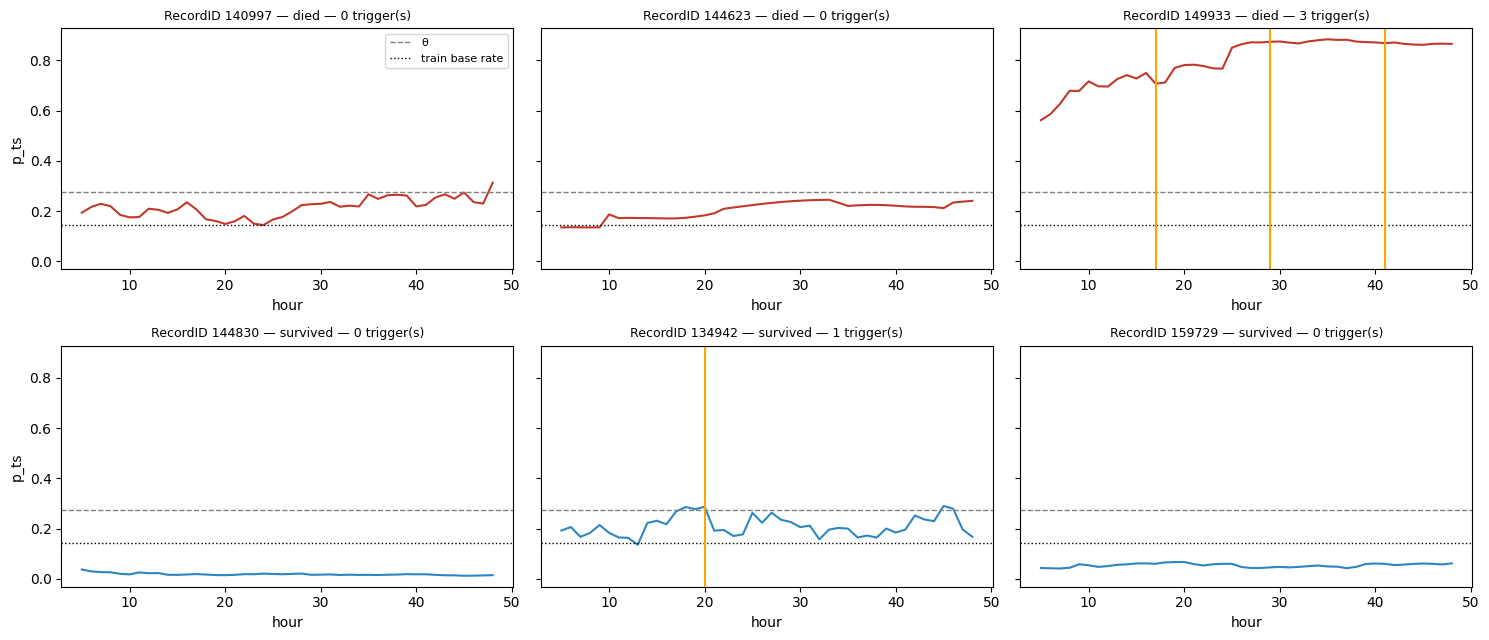

In [15]:
# Example trajectories (test): the hourly chart Notebook 4 will draw
rng = np.random.default_rng(SEED)
died_ix = rng.choice(np.where(y_all[idx_te] == 1)[0], 3, replace=False)
surv_ix = rng.choice(np.where(y_all[idx_te] == 0)[0], 3, replace=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharey=True)
for ax, k in zip(axes.ravel(), list(died_ix) + list(surv_ix)):
    traj = P_TE[k]
    ev = detect_triggers(END_HOURS, traj, THETA, TRIGGER_K_CONSECUTIVE, TRIGGER_RISE_HOURS, RISE_DELTA, COOLDOWN_HOURS)
    ax.plot(END_HOURS, traj, color="#c0392b" if y_all[idx_te][k] else "#2e86c1")
    ax.axhline(THETA, color="grey", ls="--", lw=1, label="θ")
    ax.axhline(BASE_RATE_TRAIN, color="k", ls=":", lw=1, label="train base rate")
    for e in ev:
        ax.axvline(e["hour"], color="orange", lw=1.5)
    ax.set_title(f"RecordID {ids[idx_te][k]} — {'died' if y_all[idx_te][k] else 'survived'} — {len(ev)} trigger(s)", fontsize=9)
    ax.set_xlabel("hour")
axes[0, 0].set_ylabel("p_ts"); axes[1, 0].set_ylabel("p_ts"); axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/example_trajectories.png", dpi=150); plt.show()

## 8. Save artifacts

In [16]:
import sklearn
torch.save(model.state_dict(), f"{OUT_DIR}/vitals_transformer.pth")
json.dump(NORM_STATS, open(f"{OUT_DIR}/norm_stats.json", "w"), indent=2)
json.dump({"type": "platt_on_logit", "formula": "p = sigmoid(a*z+b)", "a": CAL_A, "b": CAL_B},
          open(f"{OUT_DIR}/calibrator.json", "w"), indent=2)
json.dump({"architecture": ARCH, "variables": VARIABLES, "n_hours": N_HOURS, "window": WINDOW, "warmup": WARMUP,
           "input_layout": "[z-score carried forward | measured this hour | hours since last obs / window] x variables",
           "half_life_grid": HALF_LIFE_GRID, "chosen_half_life": BEST_HL, "triggers": TRIGGERS,
           "label": "in-hospital death, same label for every window"},
          open(f"{OUT_DIR}/model_config.json", "w"), indent=2)

metrics = {"model": "VitalsTransformerClassifier + Platt", "base_rate_train": BASE_RATE_TRAIN, "alpha": ALPHA,
           "alpha_rule": "clip(test Brier skill score vs training base rate, 0, 1)",
           "decision_threshold": DECISION_THRESHOLD, **results,
           "auroc_by_hour": by_hour["auroc"].round(4).to_dict(),
           "trigger_test_stats": trig_test.reset_index().to_dict(orient="records"),
           "split": {"seed": SEED, "n_train": int(len(idx_tr)), "n_val": int(len(idx_va)), "n_test": int(len(idx_te))},
           "versions": {"python": platform.python_version(), "torch": torch.__version__, "sklearn": sklearn.__version__,
                        "numpy": np.__version__, "pandas": pd.__version__}}
json.dump(metrics, open(f"{OUT_DIR}/metrics.json", "w"), indent=2, default=float)
hist_df.to_csv(f"{OUT_DIR}/training_history.csv", index=False)

# test patients' raw hourly data for the Notebook-4 demo (never seen in training)
np.savez_compressed(f"{OUT_DIR}/test_patients_hourly.npz", record_ids=ids[idx_te], raw=RAW[idx_te],
                    labels=y_all[idx_te], variables=np.array(VARIABLES))
meta.iloc[idx_te].to_csv(f"{OUT_DIR}/test_patients_meta.csv", index=False)
print("saved.")

saved.


## 9. Reload check, explanation example, packaging

In [17]:
importlib.reload(ts_inference)
from ts_inference import VitalsRiskModel
ts = VitalsRiskModel(OUT_DIR)

demo = np.load(f"{OUT_DIR}/test_patients_hourly.npz")
k = int(died_ix[0])
traj = ts.trajectory(demo["raw"][k])
assert np.allclose(traj["p_ts"].values, P_TE[k], atol=1e-4), "reloaded trajectory differs!"
print(f"reload OK | RecordID {demo['record_ids'][k]} (died={demo['labels'][k]}) | α = {ts.alpha:.4f}")
print("triggers:", ts.triggers(traj))
display(traj.iloc[::6].round(4))

peak_hour = int(traj.loc[traj["p_ts"].idxmax(), "hour"])
print(f"\nTop variables in the window ending at hour {peak_hour} (highest-risk hour):")
display(ts.explain(demo["raw"][k], end_hour=peak_hour, top_k=5).round(3))

reload OK | RecordID 140997 (died=1) | α = 0.2009
triggers: []


,hour,window_len,logit_raw,p_ts,delta_ts
0,5,5,-1.4496,0.1932,0.3674
6,11,11,-1.5976,0.1759,0.2523
12,17,12,-1.3476,0.2059,0.4467
18,23,12,-1.8467,0.1496,0.0586
24,29,12,-1.1881,0.2269,0.5707
30,35,12,-0.9130,0.2666,0.7846
36,41,12,-1.2086,0.2241,0.5547
42,47,12,-1.1696,0.2295,0.5851



Top variables in the window ending at hour 48 (highest-risk hour):


,variable,contribution,n_obs,first,last,trend
0,SysABP,-0.639,12,116.0,126.0,rising
1,DiasABP,0.598,12,51.0,50.0,falling
2,HCO3,0.466,1,16.0,16.0,
3,PaCO2,0.432,2,26.0,31.0,rising
4,PaO2,0.423,2,79.0,91.0,rising


In [18]:
zip_path = shutil.make_archive(os.path.join(WORK_DIR, "artifacts_transformer"), "zip", OUT_DIR)
print("zip:", zip_path, f"({os.path.getsize(zip_path)/1e6:.2f} MB)\n")
for root, _, fs in os.walk(OUT_DIR):
    for f in sorted(fs):
        p = os.path.join(root, f)
        print(f"{os.path.relpath(p, OUT_DIR):40s} {os.path.getsize(p)/1e3:9.1f} KB")

zip: /kaggle/working/artifacts_transformer.zip (3.00 MB)

calibrator.json                                0.1 KB
metrics.json                                   3.5 KB
model_config.json                              1.6 KB
norm_stats.json                                3.3 KB
test_patients_hourly.npz                    1518.4 KB
test_patients_meta.csv                        78.4 KB
training_history.csv                           1.3 KB
ts_inference.py                               12.2 KB
vitals_transformer.pth                      1196.4 KB
plots/calibration_roc_byhour.png             143.4 KB
plots/confusion_matrix.png                    38.6 KB
plots/confusion_matrix_raw.png                42.8 KB
plots/example_trajectories.png               107.7 KB
plots/training_and_decay.png                  99.0 KB


### Values used later
- `metrics.json → alpha`, `base_rate_train` (for `Δ_ts = logit(p_ts) − logit(base_rate_train)`)
- `model_config.json → triggers` (θ, k, m, δ, cooldown)
- `VitalsRiskModel.trajectory()`, `.explain()`, `.triggers()`; demo patients in `test_patients_hourly.npz`

**Limitations to state:** every window carries the final outcome label (it is "mortality risk given the data so far", not a deterioration label); windows of one patient are correlated, so window-level metrics overstate the effective sample size; the trigger thresholds are percentiles of validation survivors, not clinically validated cut-offs.